# Кластеризация ЕГЭ (8.5 если сделаны все задачи)


Рядом лежат экселевские таблицы с координатами точек. В 3 и 4 задаче используется манхетеское расстояние. В остальных Евклидово.

* Постройте Распределение точек
* Кластеризуйте руками
* Постройте Распределение точек, отметьте принадлежность кластеров цветами
* Найдите среди в каждом кластере точку расстояние от которой до всех остальных минимально
* Выведите усреднение центров всех кластеров * 1000


0.xls answer: [1073.23 6600.61]


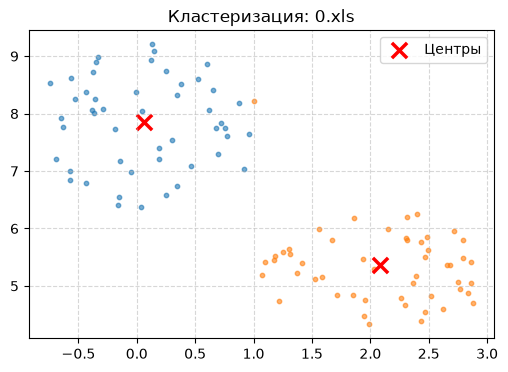

1.xls answer: [7801.21 1278.35]


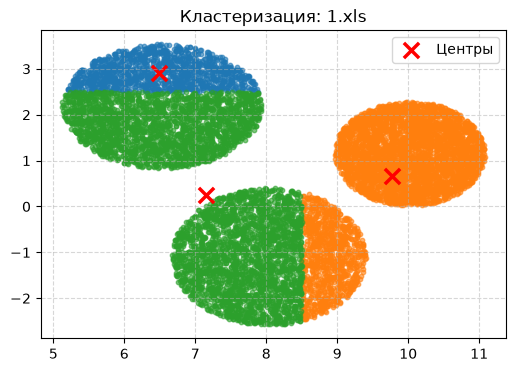

2.xlsx answer: [23829.16   440.68]


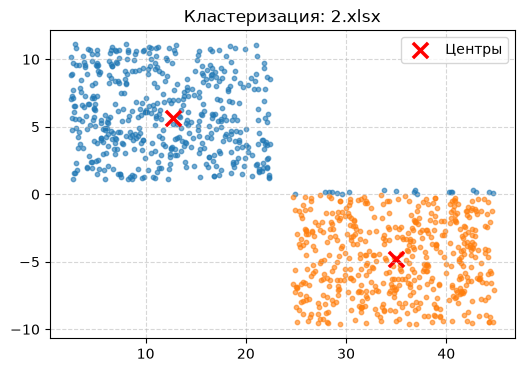

3.xlsx answer: [ 3037.05 -4797.71]


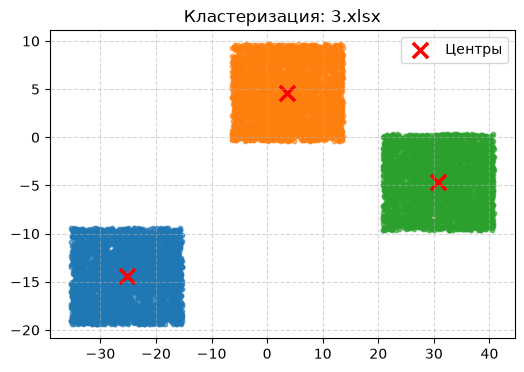

4.xlsx answer: [2863.11 4715.52]


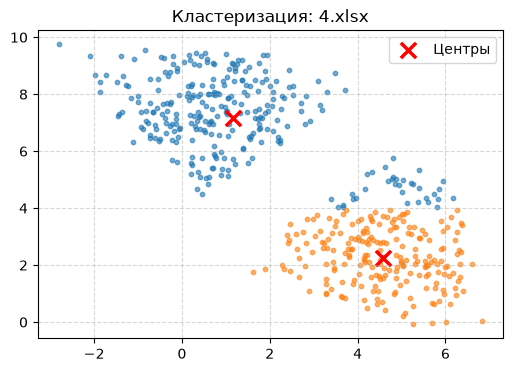

5.xlsx answer: [ -29.65 3807.29]


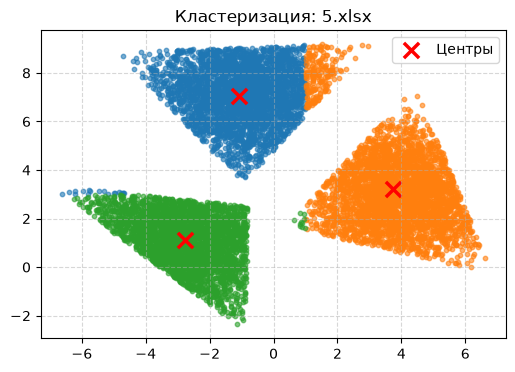

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

base_dir = '/Users/darm_s/Downloads/EGE/'

# Описания задач: имя файла, заголовки, и список условий для разделения на кластеры
tasks = [
    ('0.xls', 0, [lambda d: d['X'] < 1.0, lambda d: d['X'] >= 1.0]),
    ('1.xls', 0, [lambda d: d['Y'] > 2.5, lambda d: (d['X'] > 8.5) & (d['Y'] < 2.5), lambda d: (d['X'] <= 8.5) & (d['Y'] < 2.5)]),
    ('2.xlsx', None, [lambda d: d['Y'] > 0, lambda d: d['Y'] <= 0]),
    ('3.xlsx', None, [lambda d: d['X'] < -10, lambda d: (d['X'] >= -10) & (d['X'] < 15), lambda d: d['X'] >= 15]),
    ('4.xlsx', 0, [lambda d: d['Y'] > 4, lambda d: d['Y'] <= 4]),
    ('5.xlsx', 0, [lambda d: (d['Y'] > 3) & (d['X'] < 1), lambda d: (d['Y'] > 0) & (d['X'] >= 1), lambda d: (d['Y'] <= 3) & (d['X'] < 1)])
]

for filename, header, conditions in tasks:
    path = os.path.join(base_dir, filename) if os.path.exists(os.path.join(base_dir, filename)) else filename
    df = pd.read_excel(path, header=header)
    df.columns = ['X', 'Y']

    centers = []
    plt.figure(figsize=(6, 4))

    for cond in conditions:
        cluster_points = df[cond][['X', 'Y']].values
        
        center = cluster_points.mean(axis=0)
        centers.append(center)
        
        plt.scatter(cluster_points[:, 0], cluster_points[:, 1], s=10, alpha=0.6)

    centers = np.array(centers)
    
    plt.scatter(centers[:, 0], centers[:, 1], color='red', marker='x', s=120, linewidths=2.5, label='Центры')

    ans = centers.mean(axis=0) * 1000
    print(f"{filename} answer: {np.round(ans, 2)}")

    plt.title(f"Кластеризация: {filename}")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

# Кластеризация (0.75 за каждый алгоритм на всех данных)


На предложенных распределениях данных проверьте предложенные алгоритмы. Постройте графики кластеризации для каждой пары алгоритм-данные, разные кластеры покрасьте разным цветом. Воспользуйтесь sklearn реализациями. Параметры кластеризации для разных алгоритмов подберите такие, чтобы алгоритмы можно было сравнивать (по возможности одинаковое количество кластеров и т.д.)


In [6]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from sklearn import cluster, datasets, mixture
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler
from itertools import cycle, islice


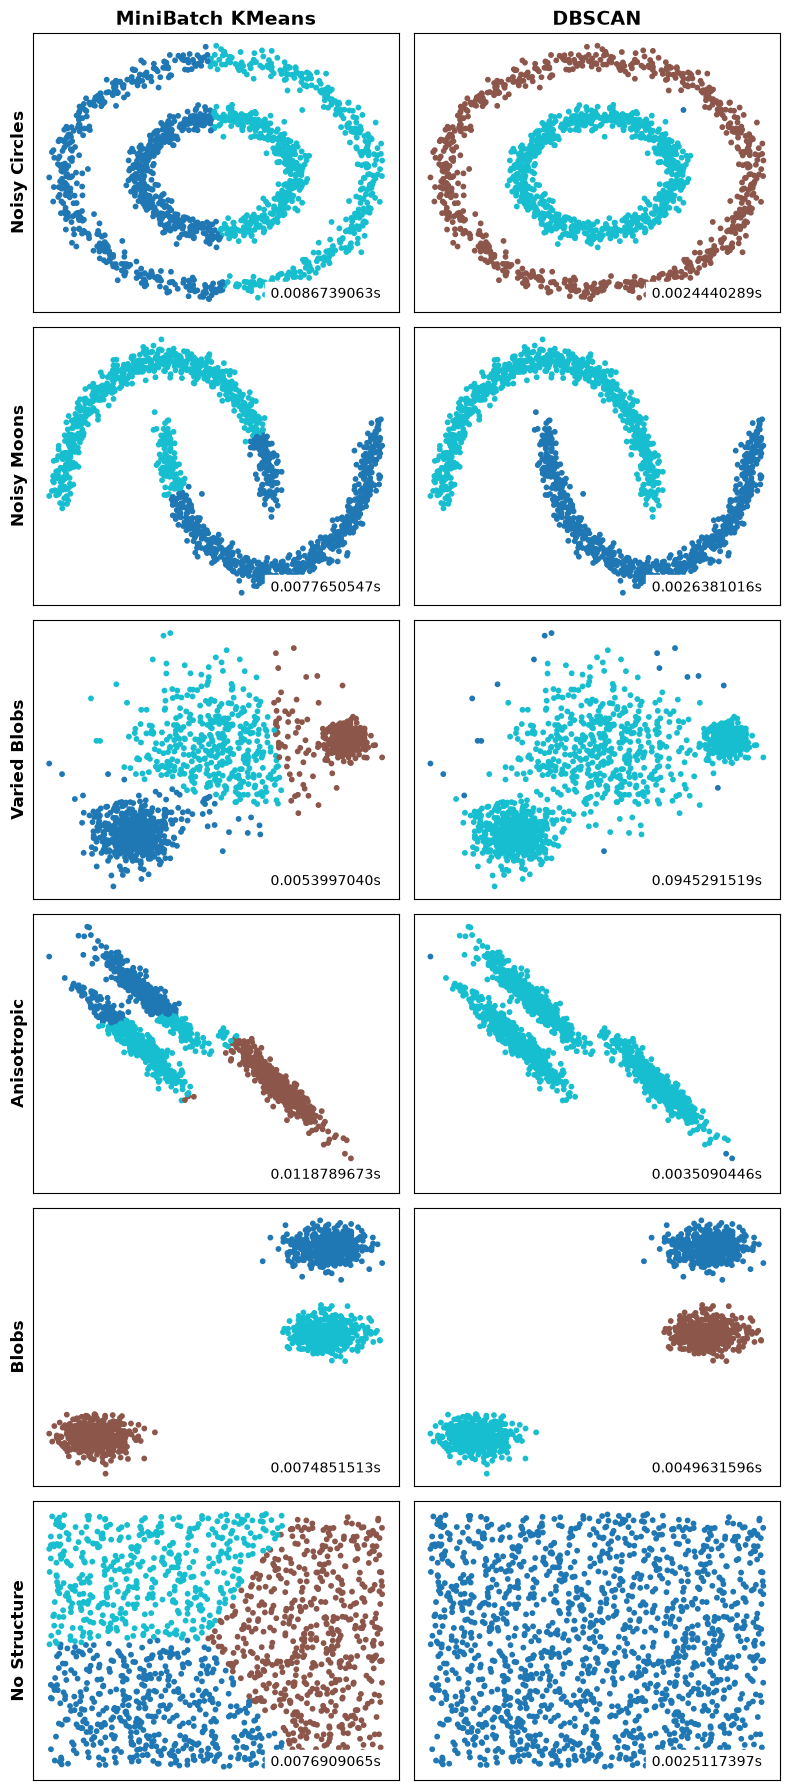

In [10]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn import cluster, datasets
from sklearn.preprocessing import StandardScaler

np.random.seed(0)
n_samples = 1500

datasets_list = [
    ("Noisy Circles", datasets.make_circles(n_samples=n_samples, factor=0.5, noise=0.05)),
    ("Noisy Moons", datasets.make_moons(n_samples=n_samples, noise=0.05)),
    ("Varied Blobs", datasets.make_blobs(n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=170)),
    ("Anisotropic", (np.dot(datasets.make_blobs(n_samples=n_samples, random_state=170)[0], [[0.6, -0.6], [-0.4, 0.8]]), None)),
    ("Blobs", datasets.make_blobs(n_samples=n_samples, random_state=8)),
    ("No Structure", (np.random.rand(n_samples, 2), None)),
]

fig, axes = plt.subplots(len(datasets_list), 2, figsize=(8, 18))

for row_idx, (name, (X, y)) in enumerate(datasets_list):
    X = StandardScaler().fit_transform(X)

    algorithms = [
        ("MiniBatch KMeans", cluster.MiniBatchKMeans(n_clusters=2 if "Circles" in name or "Moons" in name else 3, n_init="auto")),
        ("DBSCAN", cluster.DBSCAN(eps=0.2 if "Circles" in name or "Moons" in name else 0.3))
    ]

    for col_idx, (algo_name, algo) in enumerate(algorithms):
        ax = axes[row_idx, col_idx]

        t0 = time.time()
        y_pred = algo.fit_predict(X)
        t1 = time.time()

        ax.scatter(X[:, 0], X[:, 1], c=y_pred, cmap='tab10', s=10)
        ax.set_xticks(())
        ax.set_yticks(())

        if row_idx == 0:
            ax.set_title(algo_name, fontsize=14, fontweight='bold')
            
        if col_idx == 0:
            ax.set_ylabel(name, fontsize=12, fontweight='bold')

        ax.text(0.95, 0.05, f"{t1 - t0:.10f}s", transform=ax.transAxes, 
                ha='right', fontsize=10, backgroundcolor='white')

plt.tight_layout()
plt.show()